# Exploratory Data Analysis on Retail Sales Data
**Oasis Infobyte · Data Analytics Internship · Level 1 · Task 1**

**Objective:** uncover sales patterns, customer behaviour and actionable business insights from a retail sales dataset.
**Dataset:** Retail Sales Dataset (Kaggle), 1,000 transactions and 9 columns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\Dell\anaconda3\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.26.2
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
df=pd.read_csv("retail_sales_dataset.csv")

In [3]:
df.shape

(1000, 9)

In [4]:
df.dtypes

Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

In [5]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [6]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [7]:
df.duplicated().sum()

0

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [9]:
df["Date"] = pd.to_datetime(df["Date"])

In [10]:
df.dtypes

Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

In [11]:
df["Date"].min()

Timestamp('2023-01-01 00:00:00')

In [12]:
df["Date"].max()

Timestamp('2024-01-01 00:00:00')

**Observations (Initial inspection):**
- The dataset has 1,000 rows and 9 columns, with no missing values and no duplicated rows, so no cleaning was needed.
- `Date` was stored as text (object), so it was converted to datetime to enable time series analysis.
- Data covers 2023-01-01 to 2024-01-01; January 2024 contains a single day, so it is excluded from the trend charts.

In [13]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

stats = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].mode().iloc[0],
    "std": df[num_cols].std()
}).round(2)

stats

,mean,median,mode,std
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


**Observations (Descriptive statistics):**
- Age is roughly symmetric (mean 41.4, median 42, mode 43).
- Total Amount is right-skewed: the mean (456) is about 3.4x the median (135) and 
  the std (560) exceeds the mean. Most orders are small, while a few high-value orders pull the average up.
- Price per Unit shows the same pattern (mean 180 vs median 50). The median is a better measure of a "typical" order than the mean.

In [14]:
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")
df["Weekday"] = df["Date"].dt.day_name()

In [15]:
monthly = df.groupby("Month")["Total Amount"].sum()

In [16]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount',
       'Month', 'Quarter', 'Weekday'],
      dtype='object')

In [17]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 24, 34, 44, 54, 120],
    labels=["<25", "25-34", "35-44", "45-54", "55+"]
)

In [18]:
df.columns
df[["Date", "Month", "Quarter", "Weekday", "Age Group"]].head()

,Date,Month,Quarter,Weekday,Age Group
0,2023-11-24,2023-11,2023Q4,Friday,25-34
1,2023-02-27,2023-02,2023Q1,Monday,25-34
2,2023-01-13,2023-01,2023Q1,Friday,45-54
3,2023-05-21,2023-05,2023Q2,Sunday,35-44
4,2023-05-06,2023-05,2023Q2,Saturday,25-34


In [19]:
monthly = df.groupby("Month")["Total Amount"].sum()
monthly.tail()

Month
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

In [20]:
monthly = monthly.iloc[:-1]

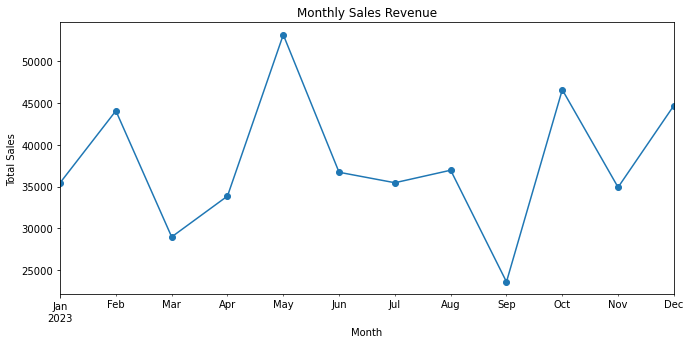

In [21]:
plt.figure(figsize=(11, 5))
monthly.plot(marker="o")
plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

**Observations (Monthly trend):**
- Monthly sales fluctuate with no clear upward or downward trend during 2023.
- Sales peak in May (53,150) and are lowest in September (23,620), a gap of more than 2x.
- February, October and December are also strong months, while March is weak.

In [22]:
quarterly = df.groupby("Quarter")["Total Amount"].sum()
quarterly = quarterly.iloc[:-1]
quarterly.tail()

Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
Freq: Q-DEC, Name: Total Amount, dtype: int64

In [23]:
quarterly.index = quarterly.index.astype(str)

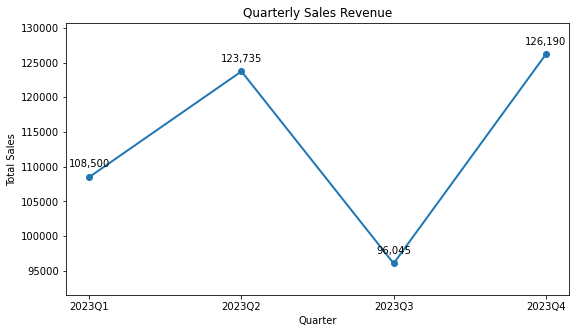

In [24]:
plt.figure(figsize=(9, 5))
plt.plot(quarterly.index, quarterly.values, marker="o", linewidth=2)
for x, y in zip(quarterly.index, quarterly.values):
    plt.annotate(f"{y:,.0f}", (x, y), textcoords="offset points", xytext=(0, 10), ha="center")

plt.title("Quarterly Sales Revenue")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.margins(y=0.15)
plt.show()

In [25]:
(quarterly / quarterly.sum() * 100).round(1)

Quarter
2023Q1    23.9
2023Q2    27.2
2023Q3    21.1
2023Q4    27.8
Name: Total Amount, dtype: float64

**Observations (Quarterly trend):**
- Q4 is the strongest quarter (126,190; 27.8% of revenue), closely followed by Q2 (123,735; 27.2%).
- Q3 is the weakest (96,045; 21.1%), about 24% below Q4, matching the September dip.
- Sales recover by +31% from Q3 to Q4.

In [26]:
  age_counts = df["Age Group"].value_counts().sort_index()

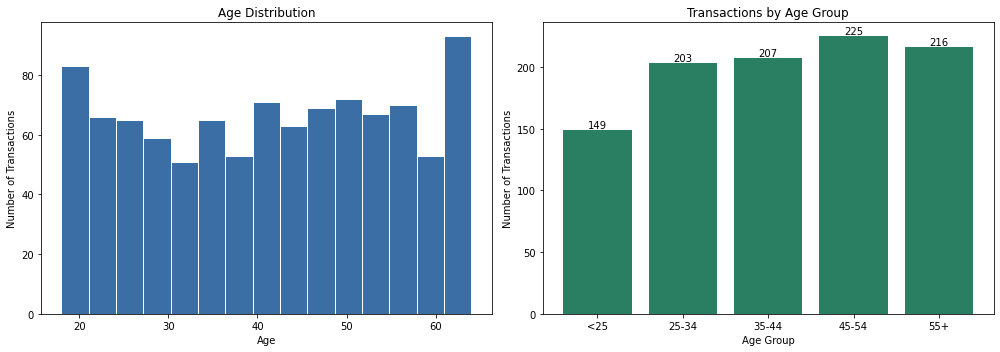

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["Age"], bins=15, color="#3b6ea5", edgecolor="white")
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Transactions")

axes[1].bar(age_counts.index.astype(str), age_counts.values, color="#2a7f62")
axes[1].set_title("Transactions by Age Group")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Number of Transactions")
for i, v in enumerate(age_counts.values):
    axes[1].text(i, v, str(v), ha="center", va="bottom")

plt.tight_layout()
plt.show()

**Observations (Age distribution):**
- The 45-54 group has the most transactions (225) and under-25s the fewest (149); the other 
  groups are close (203 to 216), so the customer base is balanced across ages.

In [28]:
gender_counts = df["Gender"].value_counts()
gender_pct = (gender_counts / len(df) * 100).round(1)

print("Transactions per gender:")
print(gender_counts)
print("\nShare of transactions (%):")
print(gender_pct)

Transactions per gender:
Female    510
Male      490
Name: Gender, dtype: int64

Share of transactions (%):
Female    51.0
Male      49.0
Name: Gender, dtype: float64


In [29]:
gender_stats = df.groupby("Gender")["Total Amount"].agg(
    total_revenue="sum",
    avg_order="mean",
    median_order="median",
    transactions="count"
).round(2)

gender_stats

,total_revenue,avg_order,median_order,transactions
Gender,,,,
Female,232840,456.55,150.0,510
Male,223160,455.43,120.0,490


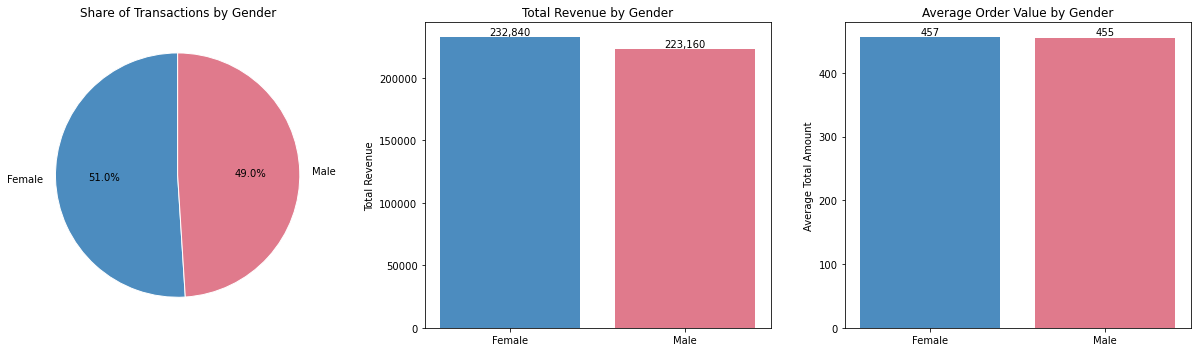

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
colors = ["#4c8cbf", "#e07a8c"]

axes[0].pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white"}
)
axes[0].set_title("Share of Transactions by Gender")
axes[1].bar(gender_stats.index, gender_stats["total_revenue"], color=colors)
axes[1].set_title("Total Revenue by Gender")
axes[1].set_ylabel("Total Revenue")
for i, v in enumerate(gender_stats["total_revenue"]):
    axes[1].text(i, v, f"{v:,.0f}", ha="center", va="bottom")

axes[2].bar(gender_stats.index, gender_stats["avg_order"], color=colors)
axes[2].set_title("Average Order Value by Gender")
axes[2].set_ylabel("Average Total Amount")
for i, v in enumerate(gender_stats["avg_order"]):
    axes[2].text(i, v, f"{v:,.0f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

**Observations (Gender):**
- The split is 51.0% Female and 49.0% Male.
- Female customers generate slightly more revenue (232,840 vs 223,160),
  but only because they have more transactions (510 vs 490). 
  The average order value is virtually identical (457 vs 455).

Product Category  Beauty  Clothing  Electronics
Gender                                         
Female               166       174          170
Male                 141       177          172


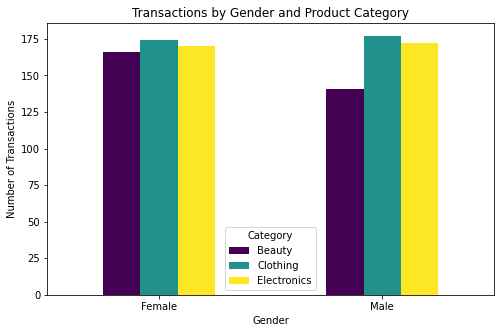

In [31]:

gender_category = pd.crosstab(df["Gender"], df["Product Category"])
print(gender_category)

gender_category.plot(kind="bar", figsize=(8, 5), colormap="viridis")
plt.title("Transactions by Gender and Product Category")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.show()

**Observations (Gender x Category):**
- Clothing and Electronics are bought at similar rates by both genders (Clothing 174 vs 177, Electronics 170 vs 172).
- The main difference is Beauty: Female 166 vs Male 141 transactions, so men buy about 15% less Beauty.

In [32]:
df["Product"] = df["Product Category"] + " @ " + df["Price per Unit"].astype(str)

top_products = (
    df.groupby("Product")
      .agg(units_sold=("Quantity", "sum"), revenue=("Total Amount", "sum"))
      .sort_values("units_sold", ascending=False)
      .head(10)
)
top_products

,units_sold,revenue
Product,,
Clothing @ 300,193,57900
Clothing @ 50,189,9450
Clothing @ 25,184,4600
Electronics @ 300,183,54900
Electronics @ 25,181,4525
Electronics @ 50,175,8750
Clothing @ 30,171,5130
Beauty @ 50,170,8500
Beauty @ 500,169,84500


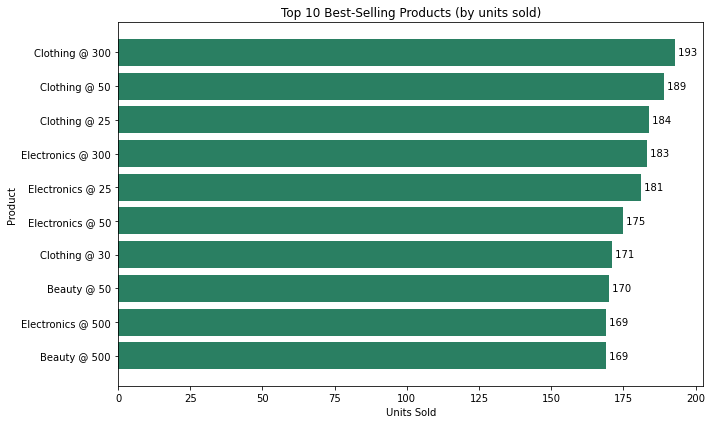

In [33]:
plt.figure(figsize=(10, 6))

plot_data = top_products["units_sold"].sort_values(ascending=True)
plt.barh(plot_data.index, plot_data.values, color="#2a7f62")

for i, v in enumerate(plot_data.values):
    plt.text(v, i, f" {v}", va="center")

plt.title("Top 10 Best-Selling Products (by units sold)")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

**Observations (Top 10 products):**
- The dataset has no product name, so a product is defined as Product Category + Price per Unit.
- Units sold are spread evenly: the 10th best seller (169 units) is only about 12% below the best seller (Clothing @ 300, 193 units).
- The best seller by volume is not the top earner: Beauty @ 500 and Electronics @ 500 each generate 84,500, versus 57,900 for Clothing @ 300.
- Similar unit sales across price tiers (Clothing @ 25: 184 units = 4,600 vs Clothing @ 300: 193 units = 57,900) show that revenue is driven by price tier, not volume.

                  revenue  units_sold  avg_order
Product Category                                
Electronics        156905         849     458.79
Clothing           155580         894     443.25
Beauty             143515         771     467.48


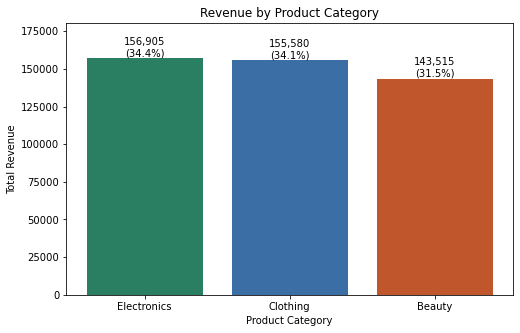

In [34]:
cat_summary = df.groupby("Product Category").agg(
    revenue=("Total Amount", "sum"),
    units_sold=("Quantity", "sum"),
    avg_order=("Total Amount", "mean")
).round(2).sort_values("revenue", ascending=False)
print(cat_summary)

plt.figure(figsize=(8, 5))
plt.bar(cat_summary.index, cat_summary["revenue"], color=["#2a7f62", "#3b6ea5", "#c0562b"])

total = cat_summary["revenue"].sum()
for i, v in enumerate(cat_summary["revenue"]):
    plt.text(i, v, f"{v:,.0f}\n({v/total*100:.1f}%)", ha="center", va="bottom")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.margins(y=0.15)
plt.show()

**Observations (Revenue by category):**
- Electronics (156,905; 34.4%) and Clothing (155,580; 34.1%) generate almost the same revenue; Beauty is lowest (143,515; 31.5%).
- The gaps are small (Beauty is about 9% below Electronics), so no category is a clear weak spot.

In [35]:
corr_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

corr = df[corr_cols].corr()
corr.round(2)

,Age,Quantity,Price per Unit,Total Amount
Age,1.00,-0.02,-0.04,-0.06
Quantity,-0.02,1.00,0.02,0.37
Price per Unit,-0.04,0.02,1.00,0.85
Total Amount,-0.06,0.37,0.85,1.00


In [36]:
n_customers = df["Customer ID"].nunique()
n_transactions = len(df)

print("Unique customers:", n_customers)
print("Transactions:", n_transactions)
print("Transactions per customer (avg):", round(n_transactions / n_customers, 2))


repeat_customers = (df["Customer ID"].value_counts() > 1).sum()
print("Customers with more than one purchase:", repeat_customers)


age_sizes = df["Age Group"].value_counts().sort_index()
print("\nTransactions per age group:")
print(age_sizes)

Unique customers: 1000
Transactions: 1000
Transactions per customer (avg): 1.0
Customers with more than one purchase: 0

Transactions per age group:
<25      149
25-34    203
35-44    207
45-54    225
55+      216
Name: Age Group, dtype: int64


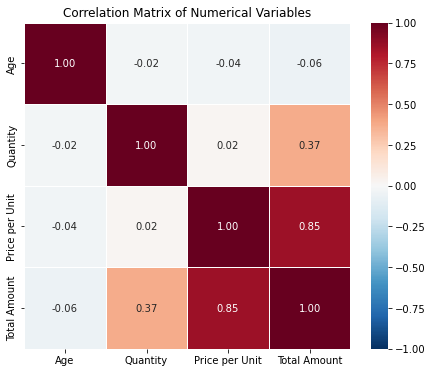

In [37]:
plt.figure(figsize=(7.5, 6))

sns.heatmap(
    corr,
    annot=True,       
    fmt=".2f",        
    cmap="RdBu_r",   
    vmin=-1, vmax=1,  
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

**Observations (Correlation):**
- Total Amount is strongly correlated with Price per Unit (r = 0.85) and moderately with Quantity (r = 0.37). This is expected because Total Amount = Quantity x Price.
- Age has almost no linear correlation with any variable (|r| <= 0.06), and Quantity and Price are independent (r = 0.02).
- Correlation only captures linear relationships, so segment patterns are explored next.

Product Category  Beauty  Clothing  Electronics
Age Group                                      
<25                28905     22160        23585
25-34              28540     41640        26910
35-44              29450     30925        36460
45-54              35950     29545        31740
55+                20670     31310        38210


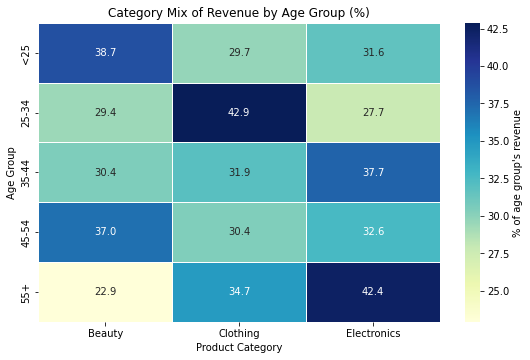

In [38]:
age_cat = df.pivot_table(
    index="Age Group",
    columns="Product Category",
    values="Total Amount",
    aggfunc="sum"
)
print(age_cat)

age_cat_share = age_cat.div(age_cat.sum(axis=1), axis=0) * 100

plt.figure(figsize=(9, 5.5))
sns.heatmap(
    age_cat_share,
    annot=True, fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "% of age group's revenue"}
)
plt.title("Category Mix of Revenue by Age Group (%)")
plt.xlabel("Product Category")
plt.ylabel("Age Group")
plt.show()

**Observations (Age Group x Category):**
- Although age does not correlate with spend, category preferences differ clearly by age.
- Clothing dominates the 25-34 group (42.9%), Electronics dominates 55+ (42.4%), and Beauty is strongest among under-25s (38.7%) and 45-54 (37.0%) but weakest among 55+ (22.9%).
- These shares are descriptive: each age-category cell is based on roughly 50-75 transactions.

Unique customers: 1000 | Transactions: 1000


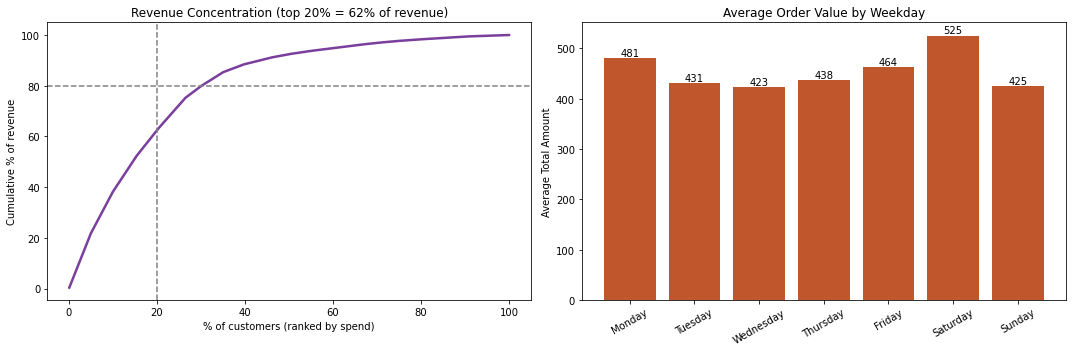

In [39]:
print("Unique customers:", df["Customer ID"].nunique(), "| Transactions:", len(df))

cust = df.groupby("Customer ID")["Total Amount"].sum().sort_values(ascending=False)
cum_pct = cust.cumsum() / cust.sum() * 100
x = np.arange(1, len(cust) + 1) / len(cust) * 100
top20_share = cum_pct.iloc[int(len(cust) * 0.2) - 1]

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = df.groupby("Weekday")["Total Amount"].mean().reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(x, cum_pct.values, color="#7a3e9d", linewidth=2.5)
axes[0].axhline(80, color="grey", linestyle="--")
axes[0].axvline(20, color="grey", linestyle="--")
axes[0].set_title(f"Revenue Concentration (top 20% = {top20_share:.0f}% of revenue)")
axes[0].set_xlabel("% of customers (ranked by spend)")
axes[0].set_ylabel("Cumulative % of revenue")

axes[1].bar(wd.index, wd.values, color="#c0562b")
axes[1].set_title("Average Order Value by Weekday")
axes[1].set_ylabel("Average Total Amount")
axes[1].tick_params(axis="x", rotation=30)
for i, v in enumerate(wd.values):
    axes[1].text(i, v, f"{v:,.0f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

**Observations (Revenue concentration and weekday):**
- Each customer appears exactly once (1,000 customers, 1,000 transactions), so this analysis is at the order level and repeat purchases cannot be studied.
- The top 20% of orders generate 62% of revenue, below the classic 80/20 rule; revenue is fairly spread out.
- Average order value is highest on Saturday (525) and lowest on Wednesday (423), about 24% higher. Given the high variability of order values, this is a pattern to test, not a confirmed effect.

## Conclusion & Business Recommendations

### Key findings
- Total revenue: about 456K across 1,000 transactions, split almost evenly between genders (51% Female / 49% Male) with the same average order value (457 vs 455).
- Sales vary noticeably across the year: the peak is in May (about 53K) and the lowest month is September (about 23.6K); Q4 is the strongest quarter (27.8%) and Q3 the weakest (21.1%).
- Revenue is driven by price tier, not volume: units sold are similar across tiers (Clothing @25: 184 units = 4,600 revenue vs Clothing @300: 193 units = 57,900).
- Age does not predict how much customers spend, but it does relate to what they buy (Clothing for 25-34, Electronics for 55+).

### Recommendations
1. **Plan stock and marketing around the strong periods.** Increase stock and campaign budget ahead of May and Q4, and run targeted promotions in Q3 (especially September), which is about 24% below Q4.
2. **Feature and bundle premium items.** Customers buy 300/500-priced products as often as cheap ones, so there is no sign that they avoid premium items. Featuring and bundling them is a promising way to raise revenue, since price tier drives revenue far more than volume.
3. **Target categories by age group.** Promote Clothing to 25-34, Electronics to 55+, and Beauty to under-25s and 45-54, instead of one generic campaign for all ages.
4. **Close the Beauty gap among men.** Men make about 15% fewer Beauty purchases than women (141 vs 166 transactions) while buying Clothing and Electronics at similar rates; test a targeted Beauty campaign for men.
5. **Test Saturday promotions.** Saturday has the highest average order value (525 vs 423 on Wednesday); run an A/B test of premium promotions on Saturdays before committing budget.

### Limitations
- Only one year of data, so seasonality cannot be confirmed across years.
- No product names: products are defined as Category + Price per Unit.
- Every customer made a single purchase, so customer loyalty, retention and lifetime value cannot be analysed.
- Age-group and weekday patterns are descriptive and based on modest sample sizes (the weekday gap may be random variation); they should be validated with more data. 